# Zero-shot single-slide embedding visualization & clustering pipeline

Aim is to demonstrate that pretrained scGPT-spatial embeddings, without any fine-tuning, capture biologically meaningful structure in a single spatial transcriptomics slide.

### Data

Download the **Human Prostate Acinar Cell Carcinoma (FFPE)** Visium dataset from 10x Genomics (filtered feature-barcode matrix `.h5`, spatial imaging data `.tar.gz`, and the clustering analysis output) and place the files in the working directory. Dependencies are listed in `requirements.txt`.

In [ ]:
import tarfile
with tarfile.open("Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma_spatial.tar.gz") as tar:
    tar.extractall(".")

### Extract and load the second Visium slide

Loads tissue sample from dataset 2: Prostate Acinar Cell Carcinoma, to further test scGPT-spatial's zero-shot embeddings. Converts the raw 10x Visium output into an .h5ad for downstream use.

In [ ]:
import scanpy as sc

adata = sc.read_visium(
    path=".",                    
    count_file="Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma_filtered_feature_bc_matrix.h5",  # replace with your actual filename
    load_images=True,
)

adata.write_h5ad("Dataset_Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 3043 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'


In [ ]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import mode
import scanpy as sc
import warnings
from matplotlib import pyplot as plt

from typing import Dict, Optional, Union
import torch
from tqdm import tqdm
from scipy.sparse import csr_matrix
import scib
sys.path.insert(0, "../")
import scgpt_spatial
from scgpt_spatial.utils import eval_scib_metrics
warnings.filterwarnings("ignore", category=ResourceWarning)
np.float = float
np.int = int

In [ ]:
# Load the data
adata= sc.read_h5ad("../tutorials/Dataset_Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma.h5ad")
adata.X = adata.X.toarray()


In [ ]:
adata

AnnData object with n_obs × n_vars = 3043 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'

In [ ]:
# Add gene symbols to adata.var (if not already present)
adata.var['gene_symbol'] = adata.var.index

In [ ]:
print('Gene metadata:')
adata.var.columns

Gene metadata:


Index(['gene_ids', 'feature_types', 'genome', 'gene_symbol'], dtype='object')

In [ ]:
adata.var.head()

,gene_ids,feature_types,genome,gene_symbol
SAMD11,ENSG00000187634,Gene Expression,GRCh38,SAMD11
NOC2L,ENSG00000188976,Gene Expression,GRCh38,NOC2L
KLHL17,ENSG00000187961,Gene Expression,GRCh38,KLHL17
PLEKHN1,ENSG00000187583,Gene Expression,GRCh38,PLEKHN1
PERM1,ENSG00000187642,Gene Expression,GRCh38,PERM1


In [ ]:
print('Observation metadata:')
adata.obs.head()

Observation metadata:


,in_tissue,array_row,array_col
AAACAATCTACTAGCA-1,1,3,43
AAACACCAATAACTGC-1,1,59,19
AAACAGAGCGACTCCT-1,1,14,94
AAACAGCTTTCAGAAG-1,1,43,9
AAACAGGGTCTATATT-1,1,47,13


In [ ]:
#set directories name
model_dir = '../scGPT_spatial_v1'
gene_col = 'gene_symbol'
#cell_type_col = 'Pathology'
batch_id_col = 'instance_id'

### Generate zero-shot embeddings for this slide

Same pretrained scGPT-spatial model as before, applied with no fine-tuning to this new, unseen tissue sample (generalization test).

In [ ]:
# Run scGPT embeddings
import os
ref_embed_adata = scgpt_spatial.tasks.embed_data(
    adata,
    model_dir,
    gene_col='gene_symbol',  
    obs_to_save= ['array_col', 'array_row'],        
    batch_size=64,
    return_new_adata=True,
    use_fast_transformer=False,
)
# Move embeddings to .obsm['X'] for Scanpy
ref_embed_adata.obsm['X'] = ref_embed_adata.X.copy()
#CHANGE THE SAVE PATH to avoid overwriting the original data
save_path = os.path.join("ref_embed_data_dataset2.h5ad")
ref_embed_adata.write(save_path) 

In [ ]:
import scanpy as sc
ref_embed_adata_dataset2 = sc.read_h5ad("ref_embed_data_dataset2.h5ad")
ref_embed_adata = ref_embed_adata_dataset2

In [ ]:
# Compare the .obs indices
print((adata.obs.index == ref_embed_adata.obs.index).all())
# For extra safety, check a few known columns
cols_to_check = ["array_col", "array_row"]
for col in cols_to_check:
    print((adata.obs[col].values == ref_embed_adata.obs[col].values).all())

In [ ]:
ref_embed_adata.obs.head()

,array_col,array_row
AAACAATCTACTAGCA-1,43,3
AAACACCAATAACTGC-1,19,59
AAACAGAGCGACTCCT-1,94,14
AAACAGCTTTCAGAAG-1,9,43
AAACAGGGTCTATATT-1,13,47


### Unsupervised clustering on scGPT embeddings

Runs Leiden clustering at resolution 0.7 on the embedding space (key_added='leiden_0.7'). Note: this dataset has no manual pathology annotation, so ground truth here comes from 10x's own Space Ranker graphclust/k-means outputs (loaded below), not expert-labeled regions.

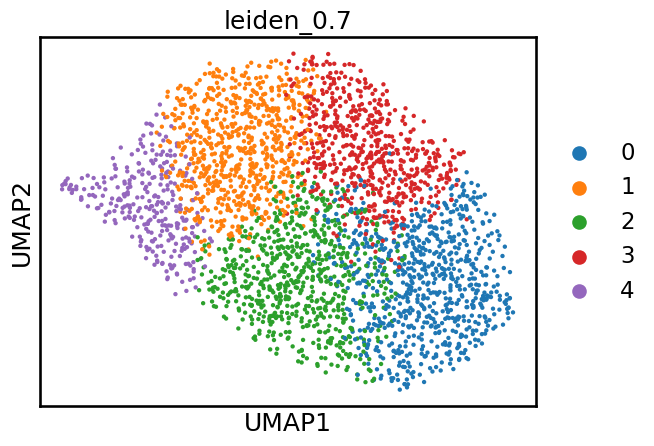

In [ ]:
# UMAP projection
sc.pp.neighbors(ref_embed_adata, use_rep="X")
sc.tl.umap(ref_embed_adata)
sc.tl.leiden(ref_embed_adata, resolution=0.7, key_added='leiden_0.7')
#sc.pl.umap(ref_embed_adata, color="leiden")
sc.pl.umap(ref_embed_adata, color="leiden_0.7")

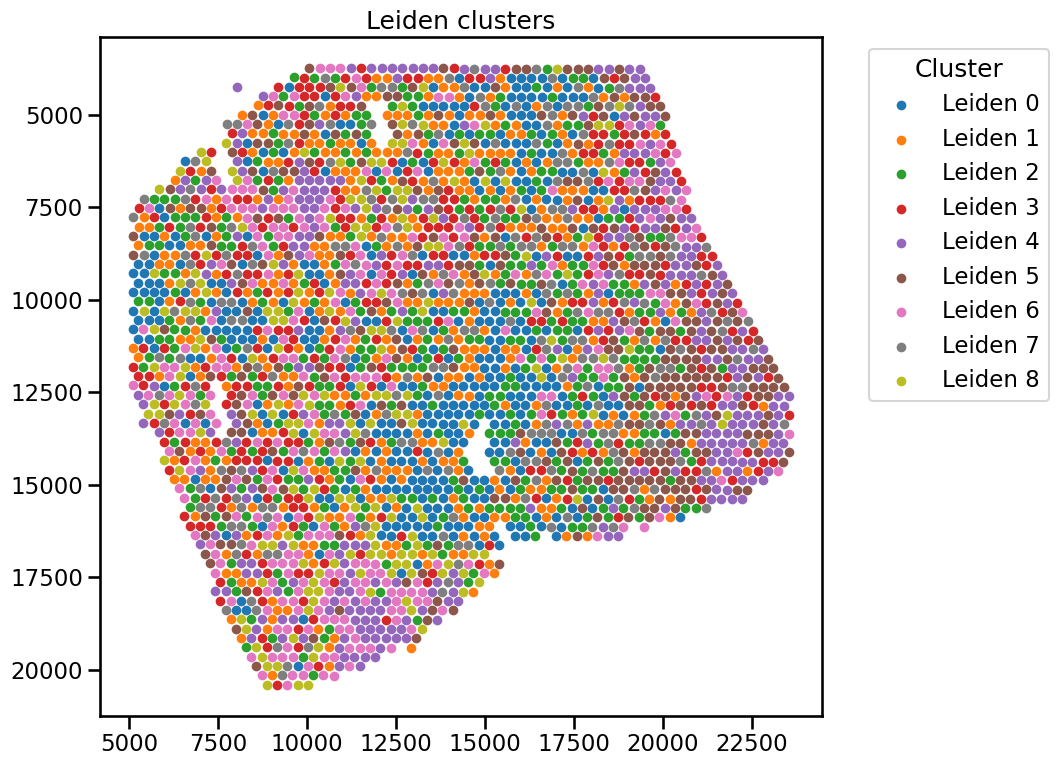

In [ ]:
# SPATIAL PLOT filtered
import numpy as np

ref_embed_adata.obsm['spatial'] = adata.obsm['spatial']
coords = ref_embed_adata.obsm["spatial"]
leiden_labels = ref_embed_adata.obs["leiden_1"].astype(str)
unique_labels = np.unique(leiden_labels)

plt.figure(figsize=(11,8))

for label in unique_labels:
    mask = leiden_labels == label
    plt.scatter(coords[mask, 0], coords[mask, 1], s=30, label=f"Leiden {label}")

plt.title("Leiden clusters")
plt.gca().invert_yaxis()
plt.legend(title="Cluster", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### Compare scGPT-derived clusters to 10x's official graph-based clustering

Loads graphclust output as an independent reference clustering and computes ARI/NMI/AMI against our Leiden result, plus a normalized cross-tab heatmap to visualize cluster correspondence.

ARI: 0.067
NMI: 0.132
AMI: 0.128


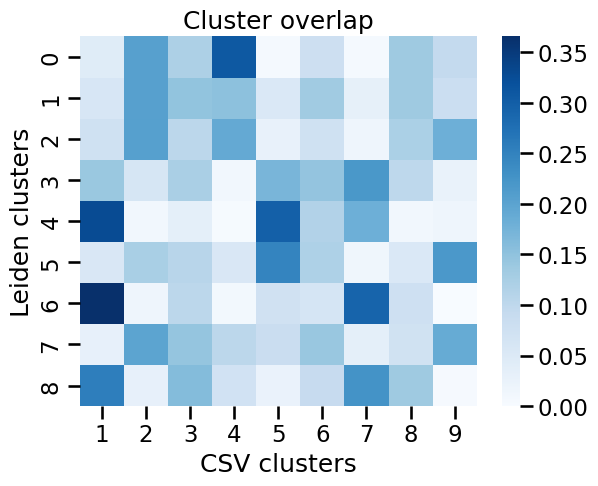

In [ ]:
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score
import seaborn as sns
clusters_df = pd.read_csv("./Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma_analysis/analysis/clustering/graphclust/clusters.csv", index_col="Barcode")
ref_embed_adata.obs["csv_clusters"] = clusters_df["Cluster"].astype(str)
leiden_labels = ref_embed_adata.obs["leiden_1"]
csv_labels    = ref_embed_adata.obs["csv_clusters"]
ari = adjusted_rand_score(leiden_labels, csv_labels)
nmi = normalized_mutual_info_score(leiden_labels, csv_labels)
ami = adjusted_mutual_info_score(leiden_labels, csv_labels)


print(f"ARI: {ari:.3f}")
print(f"NMI: {nmi:.3f}")
print(f"AMI: {ami:.3f}")

ct = pd.crosstab(
    ref_embed_adata.obs["leiden_1"],
    ref_embed_adata.obs["csv_clusters"],
    normalize="index" 
)

sns.heatmap(ct, cmap="Blues", annot=False, fmt=".2f")
plt.xlabel("CSV clusters")
plt.ylabel("Leiden clusters")
plt.title("Cluster overlap")
plt.show()

ARI_kmeans_6_clusters: 0.069
NMI_kmeans_6_clusters: 0.130
AMI_kmeans_6_clusters: 0.127


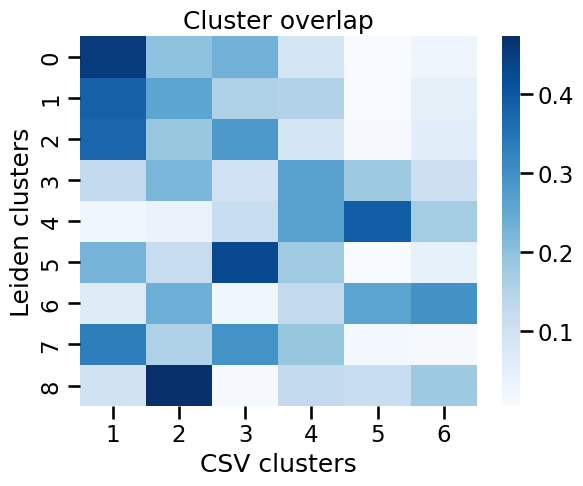

ARI_kmeans_7_clusters: 0.066
NMI_kmeans_7_clusters: 0.127
AMI_kmeans_7_clusters: 0.124


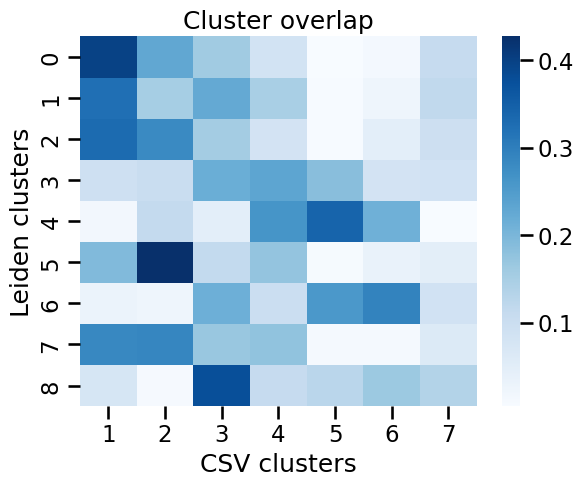

ARI_kmeans_8_clusters: 0.072
NMI_kmeans_8_clusters: 0.135
AMI_kmeans_8_clusters: 0.131


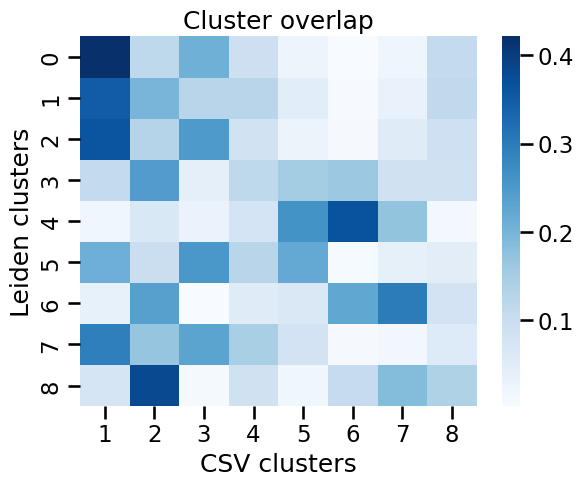

ARI_kmeans_9_clusters: 0.065
NMI_kmeans_9_clusters: 0.136
AMI_kmeans_9_clusters: 0.131


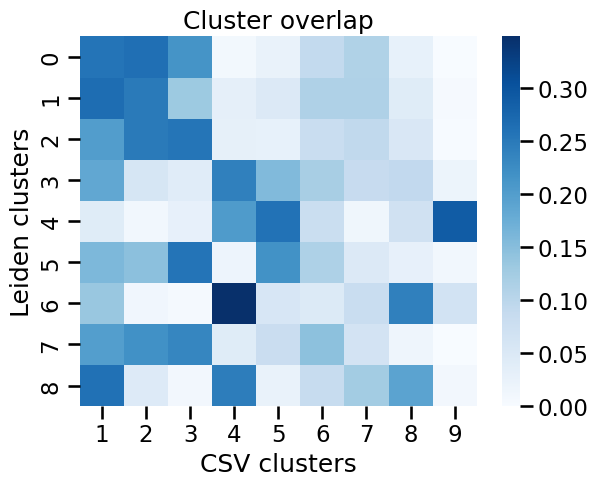

ARI_kmeans_10_clusters: 0.069
NMI_kmeans_10_clusters: 0.148
AMI_kmeans_10_clusters: 0.144


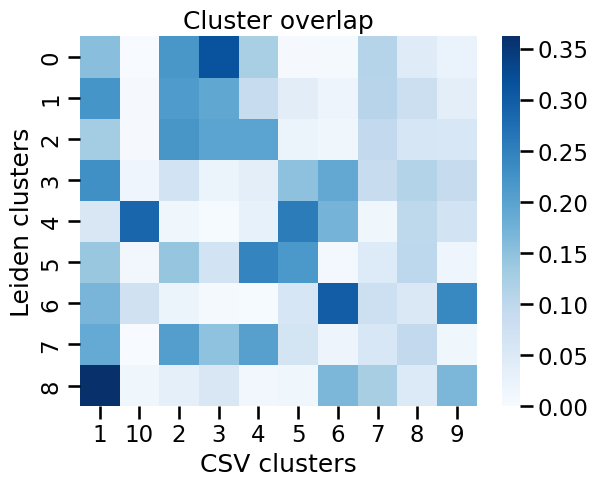

In [ ]:
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score
import seaborn as sns
k_means = ['kmeans_6_clusters', 'kmeans_7_clusters', 'kmeans_8_clusters', 'kmeans_9_clusters', 'kmeans_10_clusters']

for i in k_means:
    clusters_df = pd.read_csv(os.path.join("./Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma_analysis/analysis/clustering", i, "clusters.csv"), index_col="Barcode")
    ref_embed_adata.obs[f"csv_clusters_{i}"] = clusters_df["Cluster"].astype(str)
    leiden_labels = ref_embed_adata.obs["leiden_1"]
    csv_labels    = ref_embed_adata.obs[f"csv_clusters_{i}"]
    ari = adjusted_rand_score(leiden_labels, csv_labels)
    nmi = normalized_mutual_info_score(leiden_labels, csv_labels)
    ami = adjusted_mutual_info_score(leiden_labels, csv_labels)
    
    print(f"ARI_{i}: {ari:.3f}")
    print(f"NMI_{i}: {nmi:.3f}")
    print(f"AMI_{i}: {ami:.3f}")

    ct = pd.crosstab(
        ref_embed_adata.obs["leiden_1"],
        ref_embed_adata.obs[f"csv_clusters_{i}"],
        normalize="index" 
        )

    sns.heatmap(ct, cmap="Blues", annot=False, fmt=".2f")
    plt.xlabel("CSV clusters")
    plt.ylabel("Leiden clusters")
    plt.title("Cluster overlap")
    plt.show()

### Compare against 10x's k-means clusterings (k = 6–10)

Sweeps across 10x's precomputed k-means solutions at different k to see how scGPT-derived clusters compare across a range of granularities, rather than committing to a single reference clustering.

ARI_kmeans_6_clusters: 0.082
NMI_kmeans_6_clusters: 0.125
AMI_kmeans_6_clusters: 0.123


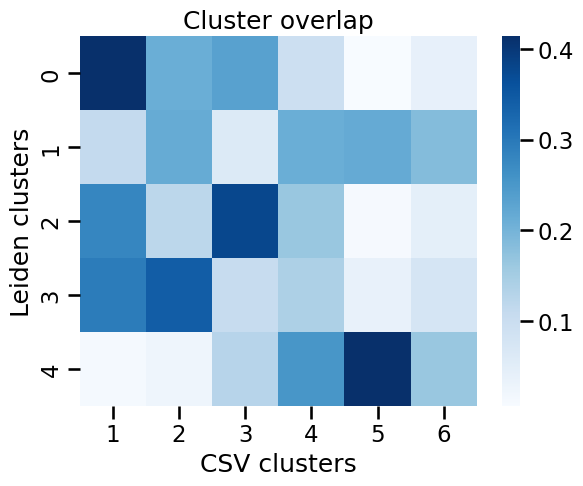

ARI_kmeans_7_clusters: 0.078
NMI_kmeans_7_clusters: 0.124
AMI_kmeans_7_clusters: 0.122


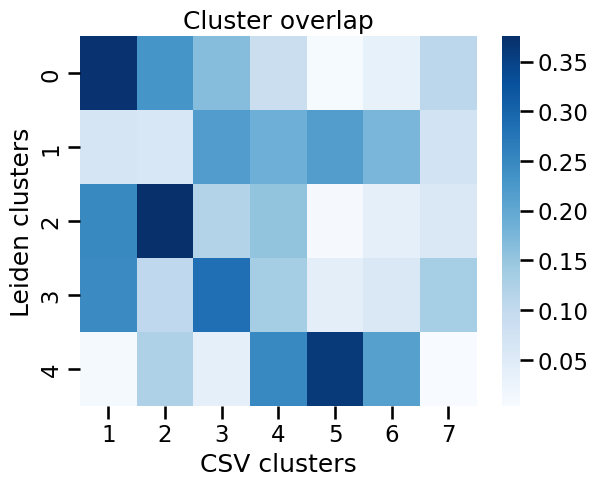

ARI_kmeans_8_clusters: 0.080
NMI_kmeans_8_clusters: 0.131
AMI_kmeans_8_clusters: 0.129


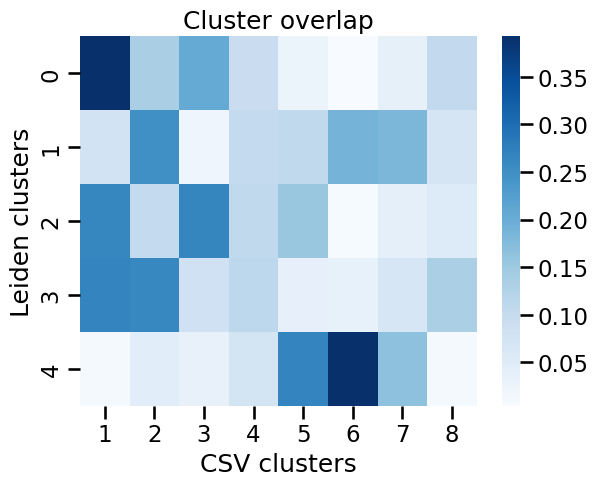

ARI_kmeans_9_clusters: 0.075
NMI_kmeans_9_clusters: 0.133
AMI_kmeans_9_clusters: 0.131


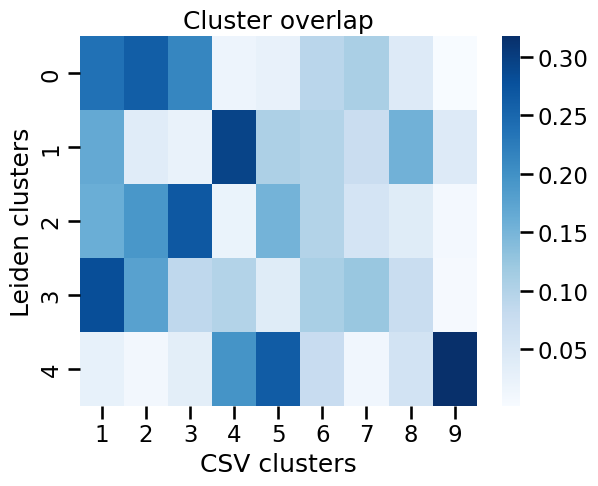

ARI_kmeans_10_clusters: 0.076
NMI_kmeans_10_clusters: 0.144
AMI_kmeans_10_clusters: 0.141


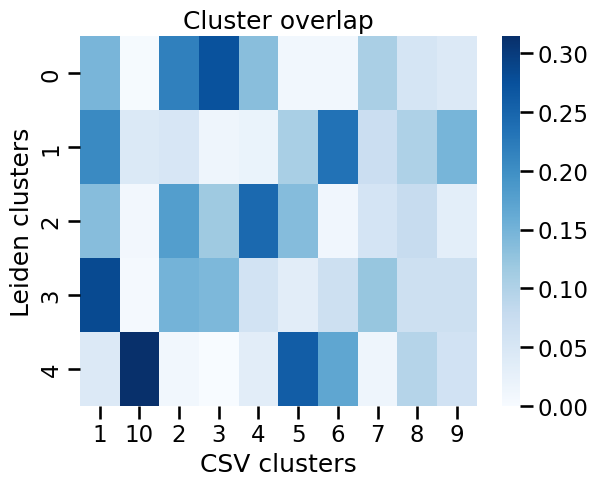

In [ ]:
import os
from sklearn.metrics import adjusted_mutual_info_score, adjusted_rand_score, normalized_mutual_info_score
import seaborn as sns
k_means = ['kmeans_6_clusters', 'kmeans_7_clusters', 'kmeans_8_clusters', 'kmeans_9_clusters', 'kmeans_10_clusters']

for i in k_means:
    clusters_df = pd.read_csv(os.path.join("./Visium_FFPE_Human_Prostate_Acinar_Cell_Carcinoma_analysis/analysis/clustering", i, "clusters.csv"), index_col="Barcode")
    ref_embed_adata.obs[f"csv_clusters_{i}"] = clusters_df["Cluster"].astype(str)
    leiden_labels = ref_embed_adata.obs["leiden_0.7"]
    csv_labels    = ref_embed_adata.obs[f"csv_clusters_{i}"]
    ari = adjusted_rand_score(leiden_labels, csv_labels)
    nmi = normalized_mutual_info_score(leiden_labels, csv_labels)
    ami = adjusted_mutual_info_score(leiden_labels, csv_labels)
    
    print(f"ARI_{i}: {ari:.3f}")
    print(f"NMI_{i}: {nmi:.3f}")
    print(f"AMI_{i}: {ami:.3f}")

    ct = pd.crosstab(
        ref_embed_adata.obs["leiden_0.7"],
        ref_embed_adata.obs[f"csv_clusters_{i}"],
        normalize="index" 
        )

    sns.heatmap(ct, cmap="Blues", annot=False, fmt=".2f")
    plt.xlabel("CSV clusters")
    plt.ylabel("Leiden clusters")
    plt.title("Cluster overlap")
    plt.show()

### Side-by-side spatial comparison of all clustering solutions

Plots Leiden (both resolutions) alongside every 10x reference clustering directly on the tissue image for visual/qualitative comparison.

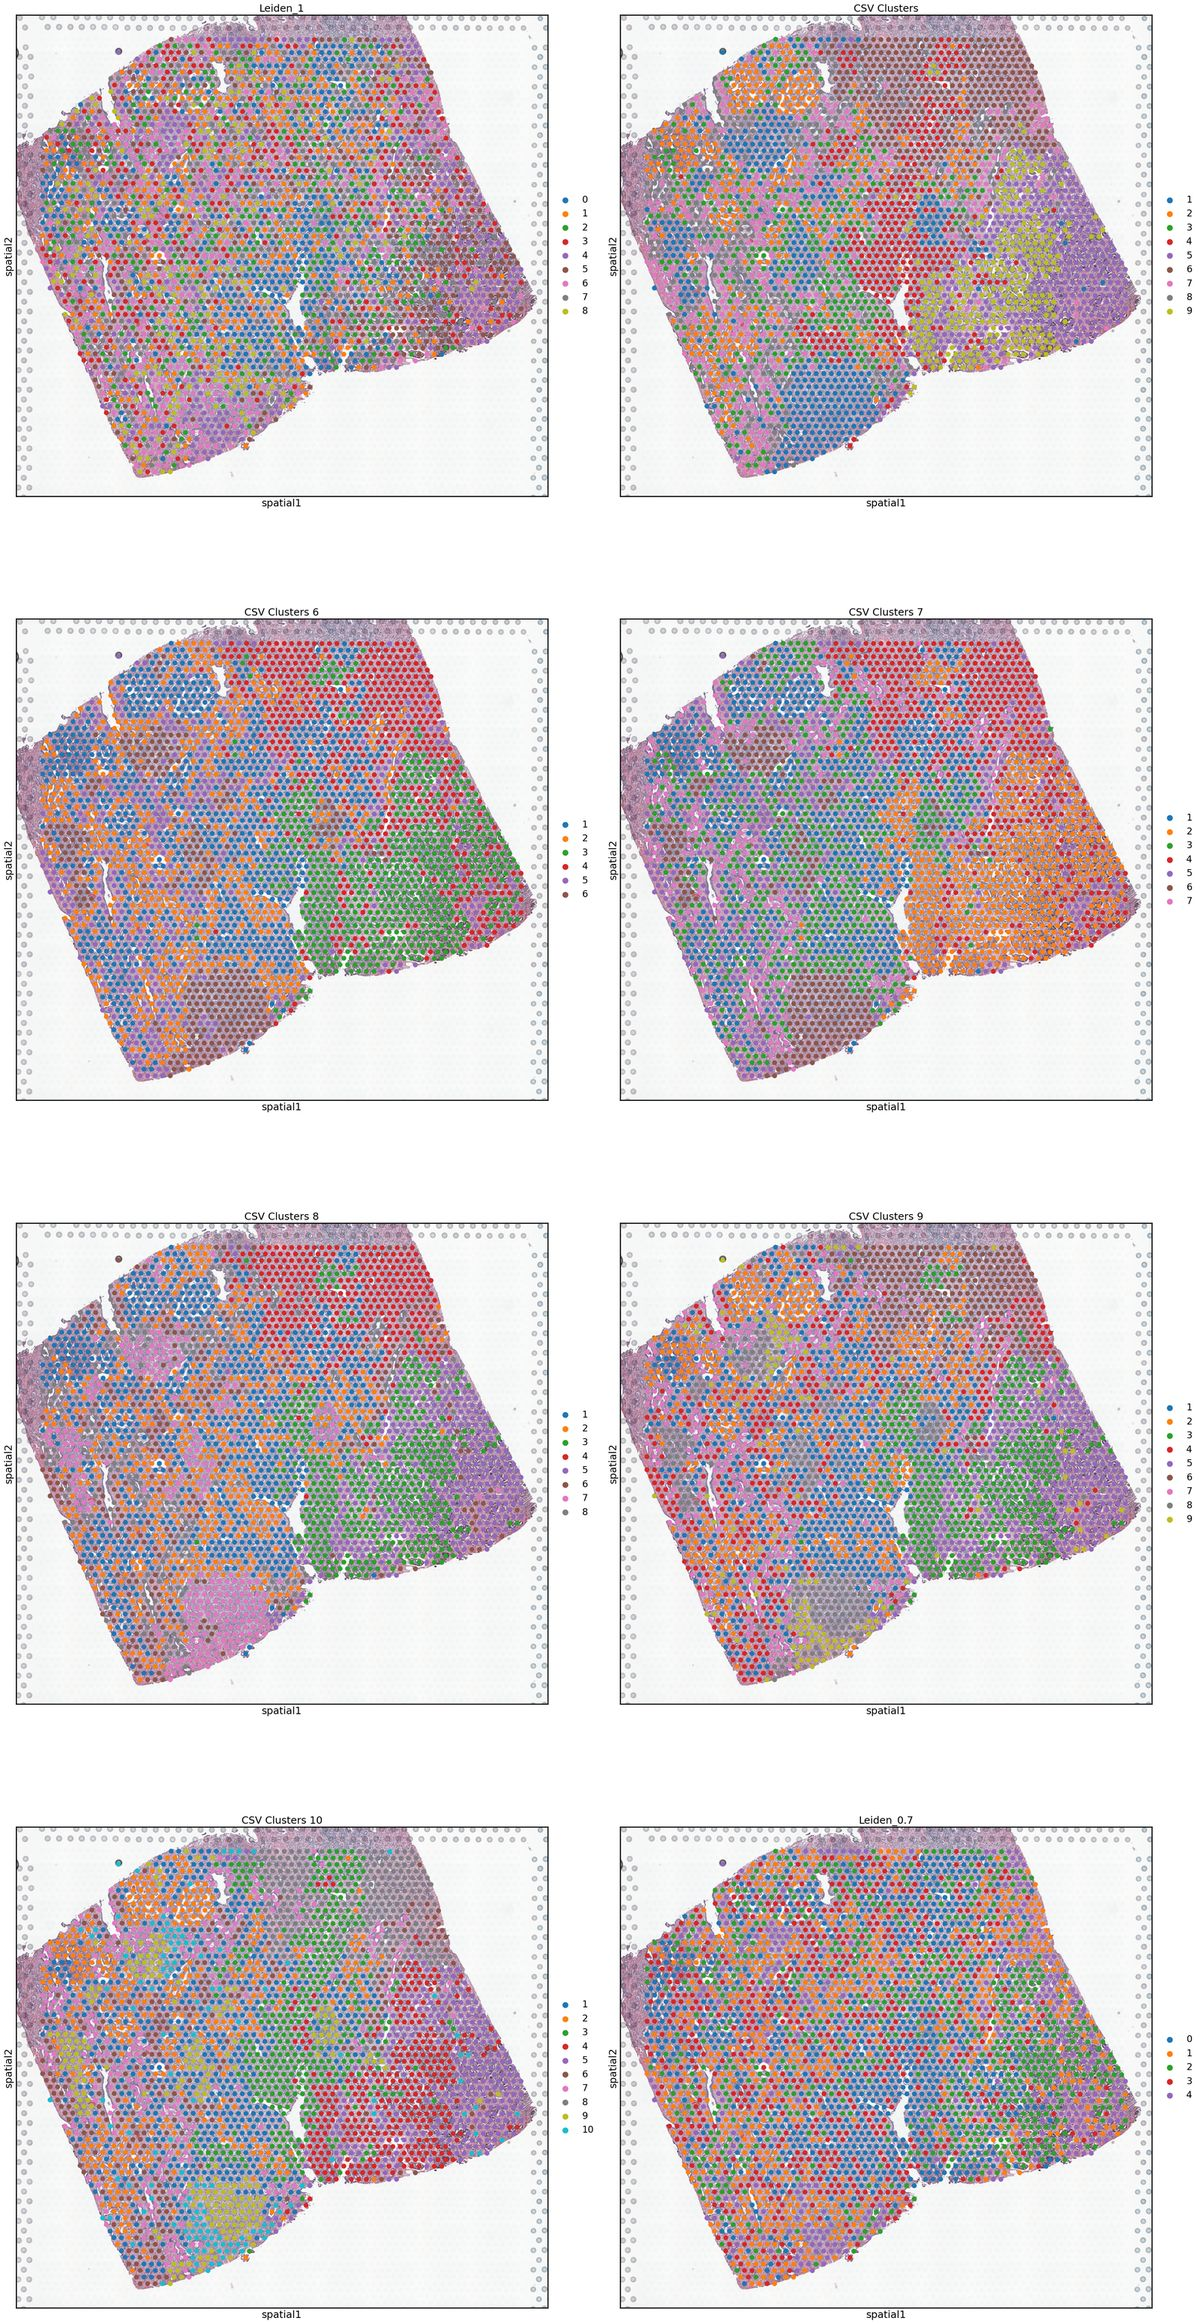

In [ ]:
fig, axs = plt.subplots(4, 2, figsize=(30, 60))  
ref_embed_adata.uns['spatial'] = adata.uns['spatial']
ref_embed_adata.obsm['spatial'] = adata.obsm['spatial']


sc.pl.spatial(ref_embed_adata, color="leiden_1",      ax=axs[0,0], title="Leiden_1", show=False)
sc.pl.spatial(ref_embed_adata, color="csv_clusters",      ax=axs[0,1], title="CSV Clusters", show=False)
sc.pl.spatial(ref_embed_adata, color="csv_clusters_kmeans_6_clusters", ax=axs[1,0], title="CSV Clusters 6",          show=False)
sc.pl.spatial(ref_embed_adata, color="csv_clusters_kmeans_7_clusters",  ax=axs[1,1], title="CSV Clusters 7",             show=False)
sc.pl.spatial(ref_embed_adata,  color="csv_clusters_kmeans_8_clusters",          ax=axs[2,0], title="CSV Clusters 8",              show=False)
sc.pl.spatial(ref_embed_adata,  color="csv_clusters_kmeans_9_clusters",      ax=axs[2,1], title="CSV Clusters 9",          show=False)
sc.pl.spatial(ref_embed_adata,  color="csv_clusters_kmeans_10_clusters",        ax=axs[3,0], title="CSV Clusters 10",            show=False)

sc.pl.spatial(ref_embed_adata,  color="leiden_0.7",        ax=axs[3,1], title="Leiden_0.7",            show=False)
plt.tight_layout()
plt.show()